
# Titanic Survival: Exploratory Data Analysis

## 1. Project Overview

The sinking of the RMS Titanic in 1912 resulted in the loss of many lives.
This project explores the Titanic passenger dataset to understand which
passenger characteristics were associated with survival.

Using Python, Pandas, NumPy, Matplotlib, and Seaborn, we will inspect
the dataset, investigate data quality, explore passenger characteristics,
and visualize patterns related to survival.

### Objectives

- Understand the structure and quality of the dataset.
- Investigate missing values and duplicate records.
- Explore passenger characteristics such as age, gender, and passenger class.
- Analyze survival rates across different passenger groups.
- Investigate relationships between fare, passenger class, family size, and survival.
- Summarize key findings and acknowledge limitations.

### Key Questions

1. What proportion of passengers survived?
2. How did survival rates differ by gender and passenger class?
3. Was age associated with survival?
4. Did travelling with family relate to survival?
5. How did fare relate to survival, and how might passenger class help explain this relationship?

### Dataset

The analysis uses the Titanic training dataset from Kaggle's
[Titanic: Machine Learning from Disaster](https://www.kaggle.com/competitions/titanic/data)
competition.

The dataset contains passenger information, including age, sex,
passenger class, fare, family relationships, and survival status.


In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [12]:

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


## 2. Loading and Inspecting the Dataset

In this section, we load the Titanic dataset and inspect its
structure, dimensions, columns, and data types.

In [13]:
df= pd.read_csv("data/train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [14]:
df.describe()


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [16]:
df.shape


(891, 12)

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## 3. Data Quality Assessment

Before performing exploratory analysis, we examine the dataset
for missing values, duplicate records, and potential inconsistencies.

This helps us understand the limitations of the data and make
informed decisions during analysis.

In [23]:
missing_data=pd.DataFrame({
    "missing_values":df.isnull().sum(),
    "missing_percentage":((df.isnull().sum())/len(df))*100
})

missing_data=missing_data[missing_data["missing_percentage"]>0]
missing_data

,missing_values,missing_percentage
Age,177,19.865320
Cabin,687,77.104377
Embarked,2,0.224467


### 3.2 Checking for Duplicate Records

Duplicate records can affect statistical analysis by causing
certain observations to be counted more than once.

We check whether the dataset contains any completely duplicated rows.

In [24]:
df.duplicated().sum()

np.int64(0)

**Observation:** The dataset contains no completely duplicated
records. Therefore, no rows need to be removed due to exact duplication.

### 3.3 Checking Numerical Distributions

We examine numerical columns to identify unusual values,
unexpected ranges, and potential outliers.

Outliers are not automatically errors; they require further investigation.

In [25]:
df[["Age", "Fare", "SibSp", "Parch", "Pclass"]].describe()

,Age,Fare,SibSp,Parch,Pclass
count,714.000000,891.000000,891.000000,891.000000,891.000000
mean,29.699118,32.204208,0.523008,0.381594,2.308642
std,14.526497,49.693429,1.102743,0.806057,0.836071
min,0.420000,0.000000,0.000000,0.000000,1.000000
25%,20.125000,7.910400,0.000000,0.000000,2.000000
50%,28.000000,14.454200,0.000000,0.000000,3.000000
75%,38.000000,31.000000,1.000000,0.000000,3.000000
max,80.000000,512.329200,8.000000,6.000000,3.000000


**Observation:** The numerical columns do not contain negative values.
The minimum values appear valid for the selected variables.
No obvious invalid negative values were identified during this check.

In [26]:
print("Sex:", df["Sex"].unique())
print("Pclass:", df["Pclass"].unique())
print("Embarked:", df["Embarked"].unique())

Sex: <StringArray>
['male', 'female']
Length: 2, dtype: str
Pclass: [3 1 2]
Embarked: <StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str


### 3.4 Data Quality Summary

The initial data-quality assessment revealed the following:

1. **Missing Values:** Age contains 177 missing values (19.87%),
   Cabin contains 687 missing values (77.10%), and Embarked contains
   2 missing values (0.22%).

2. **Duplicate Records:** No completely duplicated rows were found.

3. **Numerical Values:** No negative values were found in the
   numerical columns examined.

4. **Categorical Values:** The observed categories in Sex, Pclass,
   and Embarked are consistent with the expected Titanic dataset
   categories.

These findings will guide our analysis. Missing values will be
considered when interpreting results, and unusual values will be
investigated rather than automatically removed.

## 4. Exploratory Data Analysis

In this section, we explore passenger characteristics and investigate
the factors associated with survival.

### 4.1 Overall Survival Distribution

We begin by examining the number and proportion of passengers
who survived and those who did not.


In [29]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [32]:
survival_percentage=(df["Survived"].value_counts()/len(df))*100

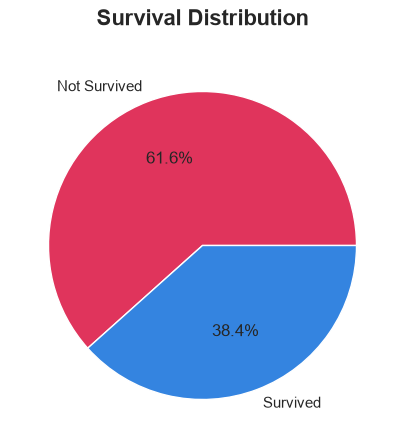

In [45]:


plt.figure(figsize=(5, 5))

survival_percentage.plot(kind="pie",
                        labels=["Not Survived" , "Survived"], 
                         autopct="%1.1f%%",
                          colors=["#e0345c" ,"#3484e0"] )

plt.title("Survival Distribution", 
          fontsize=16, 
          fontweight="bold",
          pad=20)
plt.show()


**Observations:**

1. Out of 891 passengers, 342 survived, while 549 did not survive.
2. Approximately 38.38% of passengers survived, whereas 61.62% lost their lives.
3. The number of passengers who did not survive was considerably higher than the number who survived.

**Conclusion:** The overall survival rate was relatively low, with more than 60% of the passengers losing their lives in the Titanic disaster.

### 4.2 Age Distribution

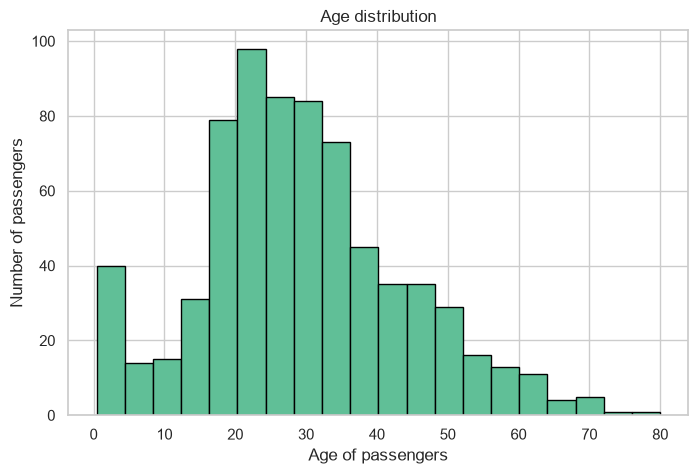

In [53]:
age_dist=df["Age"].plot(kind="hist", 
                      bins=20,
                      color="#60bf97",
                      edgecolor="black")
plt.xlabel("Age of passengers")
plt.ylabel("Number of passengers")
plt.title("Age distribution")
plt.show()

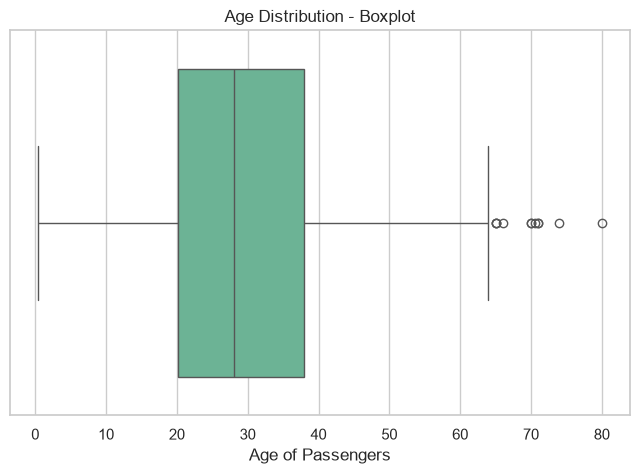

In [54]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x=df["Age"],
    color="#60bf97"
)

plt.title("Age Distribution - Boxplot")
plt.xlabel("Age of Passengers")
plt.show()

**Observations:**

1. The median age of passengers is approximately 28 years.
2. The middle 50% of passengers fall within the age range of approximately 20–38 years.
3. The non-outlier age range extends from approximately 0 to 65 years.
4. Several older passengers appear as potential outliers.

**Conclusion:** Most passengers were young adults, with a relatively small number of elderly passengers.

### 4.3 Fare Distribution 

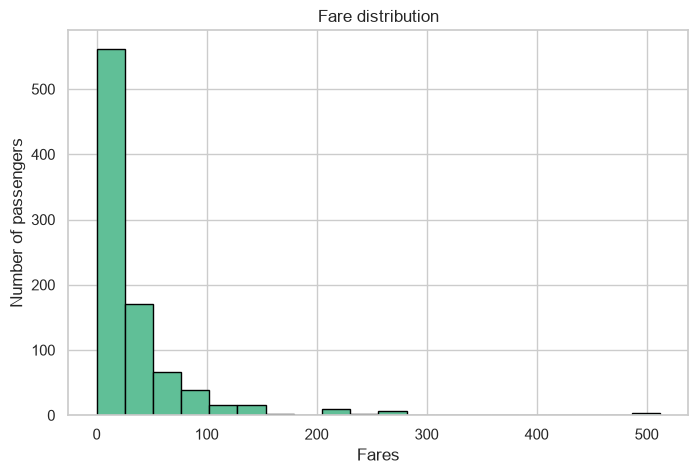

In [55]:
fare_dist=df["Fare"].plot(kind="hist", 
                      bins=20,
                      color="#60bf97",
                      edgecolor="black")
plt.xlabel("Fares")
plt.ylabel("Number of passengers")
plt.title("Fare distribution")
plt.show()

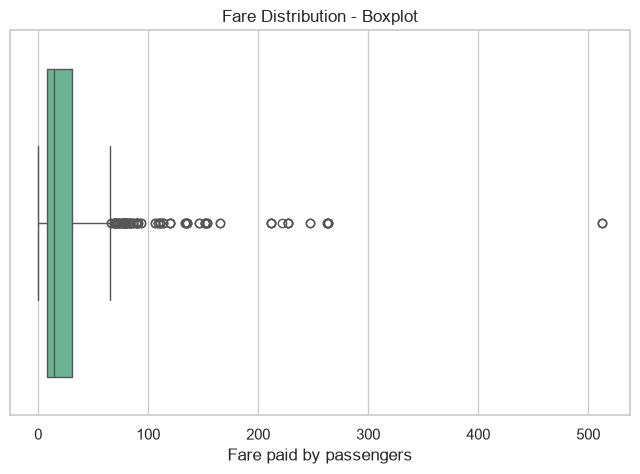

In [56]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x=df["Fare"],
    color="#60bf97"
)

plt.title("Fare Distribution - Boxplot")
plt.xlabel("Fare paid by passengers")
plt.show()

You can write this in your notebook:

Observations:
- Most passengers paid fares between 0 and 25.
- The fare distribution is positively skewed, with a long tail towards higher fares.
- A few passengers paid exceptionally high fares, with the maximum fare being approximately 512.33.
- These unusually high fares indicate considerable variation in ticket prices.
Conclusion: Most passengers travelled at relatively low fares, while a small number paid significantly higher amounts.
The boxplot confirms the presence of several high-fare outliers. The median fare is approximately 15, indicating that at least half of the passengers paid around 15 or less.


## 4.2 Bivariate Analysis

### 4.2.1 Survival vs Gender

In [65]:
sur_gen = df.groupby("Sex")["Survived"].sum()
print(sur_gen)


Sex
female    233
male      109
Name: Survived, dtype: int64


In [66]:
gender_survival_table = pd.crosstab(
    df["Sex"],
    df["Survived"]
)

gender_survival_table

Survived,0,1
Sex,,
female,81,233
male,468,109


In [67]:
sur_gen = df.groupby("Sex")["Survived"].mean()*100
print(sur_gen)


Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


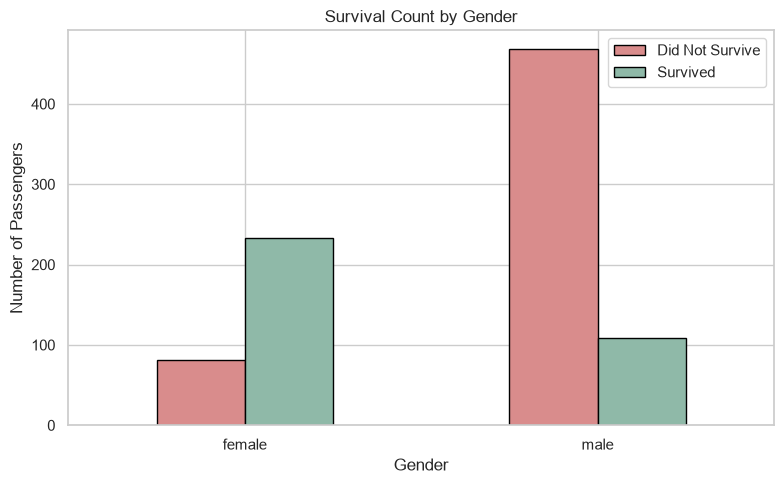

In [70]:
gender_survival_table.plot(
    kind="bar",
    figsize=(8, 5),
    color=["#D98C8C", "#8FB9A8"],
    edgecolor="black"
)

plt.title("Survival Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.legend(["Did Not Survive", "Survived"])
plt.tight_layout()
plt.show()

Observations:
1. Out of 314 female passengers, 233 survived and 81 did not survive.
2. Out of 577 male passengers, 109 survived and 468 did not survive.
3. Female passengers had a significantly higher survival rate (approximately 74.2%) compared to male passengers (approximately 18.9%).
4. The number of male passengers who did not survive was considerably higher than the number of female passengers who did not survive.
Conclusion: Gender appears to have had a strong association with survival on the Titanic. Female passengers were considerably more likely to survive than male passengers.

### 4.2.2 Survival vs Pclass

In [71]:
Pclass_survival_table = pd.crosstab(
    df["Pclass"],
    df["Survived"]
)

Pclass_survival_table

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [72]:
df.groupby("Pclass")["Survived"].mean()*100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

In [73]:
Pclass_survival_table=pd.crosstab(
    df["Pclass"], 
    df["Survived"]
)
Pclass_survival_table

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


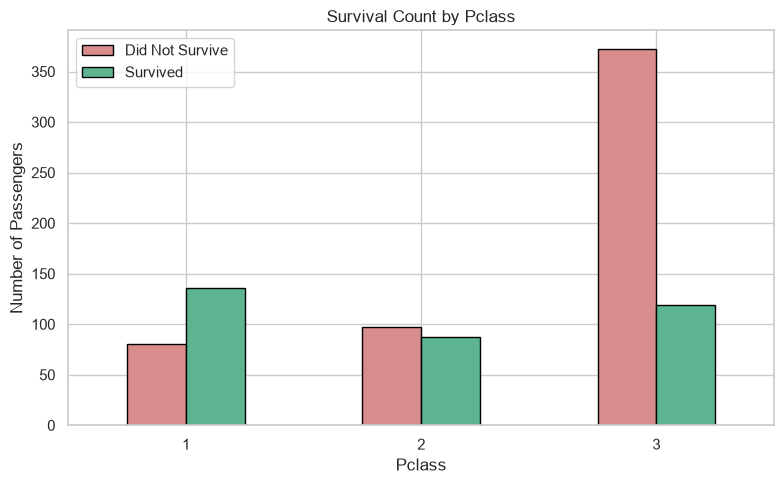

In [76]:
Pclass_survival_table.plot(
    kind="bar",
    figsize=(8, 5),
    color=["#D98C8C", "#5cb590" ,"#679ec7"],
    edgecolor="black"
)

plt.title("Survival Count by Pclass")
plt.xlabel("Pclass")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.legend(["Did Not Survive", "Survived"])
plt.tight_layout()
plt.show()

Observations:
1. First-class passengers had the highest survival rate (approximately 63%).
2. Second-class passengers had a survival rate of approximately 47%.
3. Third-class passengers had the lowest survival rate (approximately 24%).
4. Survival rates decreased from first class to third class.
Conclusion: Passenger class was strongly associated with survival. First-class passengers were more likely to survive, while third-class passengers had the lowest survival rate.